# 6. Combining the models: stacking and a genetic algorithm

* **Stacking (new):** a logistic regression per label learns how to combine the out-of-fold scores of
  all four base models.
* **Genetic algorithm (class):** per label, a chromosome holds one weight per model plus the decision
  threshold. Fitness is F1. Selection, crossover and mutation evolve the population.

Both are fitted on four patient folds and applied to the fifth.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from workflow_ml.config import LABELS
from workflow_ml.train import fold_f1, report, run_experiment, summary

experiment = run_experiment()
results = report(experiment)
summary(experiment, results)

scoring random_forest ...
scoring mlp ...
scoring gradient_boosting ...
scoring gru ...
stacking and evolving the blend ...


scope,all_patients,without_largest_patients,fold_mean,fold_std
model,,,,
random_forest,0.745,0.581,0.671,0.101
mlp,0.606,0.525,0.587,0.064
gradient_boosting,0.783,0.680,0.737,0.078
gru,0.684,0.561,0.634,0.071
stacking,0.779,0.679,0.738,0.075
ga_blend,0.789,0.681,0.742,0.076


## What the GA evolved
Weights of the final blend, refitted on all rows.

In [3]:
models = [name for name in experiment.scores if name != "ga_blend"]
weights = pd.DataFrame(experiment.final_blend.weights, index=LABELS, columns=models).round(2)
weights.assign(threshold=experiment.final_blend.thresholds.round(3))

,random_forest,mlp,gradient_boosting,gru,stacking,threshold
medical_exam,0.12,0.00,0.34,0.30,0.23,0.325
lab_test,0.01,0.12,0.74,0.13,0.00,0.339
imaging,0.20,0.03,0.58,0.10,0.09,0.178
instrument_test,0.17,0.00,0.32,0.11,0.40,0.249


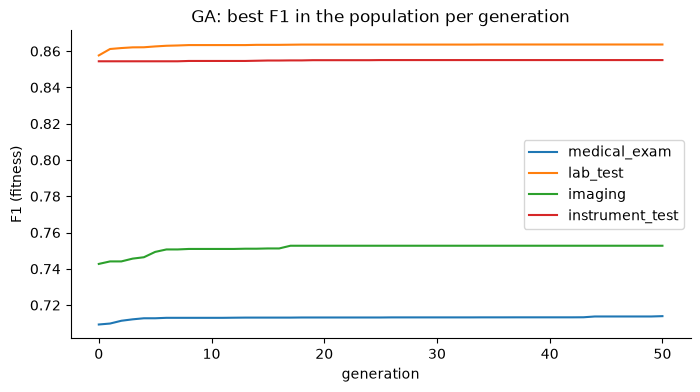

In [4]:
for label, history in zip(LABELS, experiment.final_blend.history):
    plt.plot(history, label=label)
plt.title("GA: best F1 in the population per generation")
plt.xlabel("generation")
plt.ylabel("F1 (fitness)")
plt.legend();